数据划分

In [ ]:
!pip install rdkit

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 53.1 MB/s eta 0:00:00


In [ ]:
import pandas as pd
import numpy as np
import os
import re
import pickle
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from rdkit import Chem
from rdkit.Chem import AllChem, Scaffolds, rdFingerprintGenerator
from rdkit.Chem.Scaffolds import MurckoScaffold
import warnings

warnings.filterwarnings('ignore')
np.random.seed(42) # ★ 防泄露核心：固定随机种子，保证每次划分和PCA结果一致

DATA_DIR = './'
GDSC_FILE = os.path.join(DATA_DIR, 'GDSC2_fitted_dose_response_27Oct23.csv')
EXPR_FILE = os.path.join(DATA_DIR, 'OmicsExpressionProteinCodingGenesTPMLogp1BatchCorrected.csv')
MUT_FILE = os.path.join(DATA_DIR, 'OmicsSomaticMutationsMatrixHotspot.csv')
MODEL_FILE = os.path.join(DATA_DIR, 'Model.csv')
METHYL_TXT = os.path.join(DATA_DIR, 'CCLE_RRBS_TSS_1kb_20180614.txt')
SMILES_FILE = os.path.join(DATA_DIR, 'drug_smiles.csv')

print("✅ Cell 1 完成：环境就绪")

✅ Cell 1 完成：环境就绪


In [ ]:
print("正在处理 GDSC2 标签数据...")
# 读取CSV (较慢，耐心等待)
gdsc = pd.read_csv(GDSC_FILE)
gdsc_gbm = gdsc[gdsc['CANCER_TYPE'].str.contains('Glioblastoma', case=False, na=False)].copy()

# 读取 DepMap 映射表
model = pd.read_csv(MODEL_FILE)
model_sub = model[['ModelID', 'SangerModelID']].dropna()

# 将 SANGER_MODEL_ID 映射为 ModelID (DepMap_ID)
gdsc_gbm = pd.merge(gdsc_gbm, model_sub, left_on='SANGER_MODEL_ID', right_on='SangerModelID', how='inner')

# 去重取均值，防止数据泄露
gdsc_grouped = gdsc_gbm.groupby(['ModelID', 'DRUG_NAME']).agg({'LN_IC50': 'mean'}).reset_index()

print(f"✅ Cell 2 完成：得到 {len(gdsc_grouped)} 条唯一药物-细胞系记录")
print(f"包含唯一细胞系: {gdsc_grouped['ModelID'].nunique()} 个, 唯一药物: {gdsc_grouped['DRUG_NAME'].nunique()} 种")

正在处理 GDSC2 标签数据...
✅ Cell 2 完成：得到 8603 条唯一药物-细胞系记录
包含唯一细胞系: 37 个, 唯一药物: 286 种


In [ ]:
print("正在处理细胞系特征...")
valid_cells = gdsc_grouped['ModelID'].unique()

# 1. 表达矩阵
expr = pd.read_csv(EXPR_FILE, index_col=0)
expr_gbm = expr.loc[expr.index.intersection(valid_cells)]
# 找出 MGMT 列（作为备用特征）
mgmt_col = [c for c in expr.columns if 'MGMT' in c][0]
mgmt_expr = expr_gbm[[mgmt_col]].rename(columns={mgmt_col: 'MGMT_Expr'})

# 2. 突变矩阵 (★ 修复核心：直接用列名读取，并过滤默认条目)
mut = pd.read_csv(MUT_FILE)
# 只保留默认的模型记录
mut = mut[mut['IsDefaultEntryForModel'] == 'Yes']
# 将 ModelID 设为索引
mut = mut.set_index('ModelID')
# 去掉不是特征的非数值列
cols_to_drop = ['SequencingID', 'ModelConditionID', 'IsDefaultEntryForModel', 'IsDefaultEntryForMC']
mut = mut.drop(columns=[c for c in cols_to_drop if c in mut.columns])

mut_gbm = mut.loc[mut.index.intersection(valid_cells)]
# 只保留至少有一个突变的基因列
mut_gbm = mut_gbm.loc[:, (mut_gbm != 0).any(axis=0)]

print(f"✅ Cell 3 完成：表达特征 {expr_gbm.shape}, 突变特征 {mut_gbm.shape}")

正在处理细胞系特征...
✅ Cell 3 完成：表达特征 (24, 19138), 突变特征 (37, 20)


In [ ]:
print("正在处理甲基化数据...")
# 1. 读取原始 txt (制表符分隔)
df_methylation = pd.read_csv(METHYL_TXT, sep='\t', index_col=0)

# 2. 转换为 CSV 并保存 (满足格式转换要求)
df_methylation.to_csv('CCLE_RRBS_Methylation.csv')
print("-> 已生成 CCLE_RRBS_Methylation.csv")

# 3. 专门提取 MGMT 特征
mgmt_row = df_methylation.loc[df_methylation.index.str.contains('MGMT', case=False, na=False)]
mgmt_methyl = mgmt_row.T
mgmt_methyl.columns = ['MGMT_Methylation']

# 4. 将旧版细胞系名称 (如 U87MG) 映射为 DepMap_ID
name_to_id = dict(zip(model['CellLineName'], model['ModelID']))
mgmt_methyl.index = mgmt_methyl.index.map(name_to_id)
mgmt_methyl = mgmt_methyl.dropna() # 剔除未匹配上的

print(f"✅ Cell 4 完成：成功提取 {len(mgmt_methyl)} 个细胞的 MGMT 甲基化特征")

正在处理甲基化数据...
-> 已生成 CCLE_RRBS_Methylation.csv
✅ Cell 4 完成：成功提取 849 个细胞的 MGMT 甲基化特征


In [ ]:
print("=" * 60)
print("Cell 6: 数据合并 + 防泄露划分 + PCA")
print("=" * 60)

# ============ 1. 生成 drug_info ============
print("\n[1/5] 生成药物特征 (Morgan FP + Scaffold)...")
drug_raw = pd.read_csv(SMILES_FILE)
print(f"  drug_smiles.csv 列名: {drug_raw.columns.tolist()}")

def pick_col(cands, cols):
    for c in cands:
        if c in cols:
            return c
    raise ValueError(f"找不到列，候选={cands}, 实际={cols}")

name_col = pick_col(['drug_name'], drug_raw.columns.tolist())
smiles_col = pick_col(['canonical_smiles'], drug_raw.columns.tolist())

drug_info = drug_raw[[name_col, smiles_col]].dropna().drop_duplicates(name_col).copy()
drug_info.columns = ['DRUG_NAME', 'SMILES']

def norm_drug(x):
    return re.sub(r'[^A-Z0-9]', '', str(x).upper().strip())

drug_info['DRUG_KEY'] = drug_info['DRUG_NAME'].map(norm_drug)
drug_info = drug_info.drop_duplicates('DRUG_KEY').copy()

morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
drug_info['Mol'] = drug_info['SMILES'].map(Chem.MolFromSmiles)
drug_info = drug_info[drug_info['Mol'].notna()].copy()
drug_info['Morgan_FP'] = drug_info['Mol'].map(
    lambda m: morgan_gen.GetFingerprintAsNumPy(m).astype(np.float32))
drug_info['Scaffold'] = drug_info['Mol'].map(
    lambda m: MurckoScaffold.MurckoScaffoldSmiles(mol=m) if m is not None else None)
print(f"  ✅ 可用药物数: {len(drug_info)}")

gdsc_grouped = gdsc_grouped.copy()
gdsc_grouped['DRUG_KEY'] = gdsc_grouped['DRUG_NAME'].map(norm_drug)
unmatched = set(gdsc_grouped['DRUG_KEY']) - set(drug_info['DRUG_KEY'])
print(f"  未匹配药物数: {len(unmatched)}, 示例: {list(unmatched)[:5]}")

# ============ 2. 加前缀，避免表达/突变列名冲突 ============
print("\n[2/5] 加前缀避免列名冲突...")
expr_gbm_p = expr_gbm.add_prefix('EXPR_')
mut_gbm_p  = mut_gbm.add_prefix('MUT_')
mgmt_p =  mgmt_expr.copy()

expr_cols = list(expr_gbm_p.columns)
mut_cols  = list(mut_gbm_p.columns)
mgmt_cols = ['MGMT_Expr']
cell_cols = expr_cols + mut_cols + mgmt_cols
print(f"  表达={len(expr_cols)}, 突变={len(mut_cols)}, MGMT={len(mgmt_cols)}, 合计={len(cell_cols)}")
print(f"  ✅ MGMT 代理特征: {mgmt_p.shape}, 缺失率={mgmt_p.isna().mean().iloc[0]:.2%}")

# ============ 3. 合并 ============
print("\n[3/5] 合并数据 (inner join on expr/mut, left join on MGMT)...")
gdsc_valid = gdsc_grouped.merge(
    drug_info[['DRUG_KEY', 'Morgan_FP', 'Scaffold']],
    on='DRUG_KEY', how='inner')
final_df = gdsc_valid.merge(expr_gbm_p, left_on='ModelID', right_index=True, how='inner')
final_df = final_df.merge(mut_gbm_p, left_on='ModelID', right_index=True, how='inner')
final_df = final_df.merge(mgmt_p, left_on='ModelID', right_index=True, how='left')

print(f"  ✅ final_df shape: {final_df.shape}")
print(f"  ✅ 唯一细胞系数: {final_df['ModelID'].nunique()}")
print(f"  ✅ 唯一药物数:   {final_df['DRUG_NAME'].nunique()}")
if 'MGMT_Methylation' in final_df.columns:
    miss = final_df['MGMT_Methylation'].isna().mean()
    print(f"  MGMT 缺失比例: {miss:.2%} (用训练集中位数填充)")

# ============ 4. 防泄露划分 + 只对表达做 PCA ============
print("\n[4/5] 划分 + PCA...")

def split_and_pca(df, split_type, test_size=0.2, n_pca=32):
    if len(df) == 0:
        raise ValueError("final_df 为空，检查 merge。")

    rng = np.random.default_rng(42)

    if split_type == 'random':
        train, test = train_test_split(df, test_size=test_size, random_state=42)
    elif split_type == 'leave_cell':
        cells = df['ModelID'].unique()
        n_test = max(1, int(len(cells) * test_size))
        test_cells = rng.choice(cells, size=n_test, replace=False)
        train = df[~df['ModelID'].isin(test_cells)].copy()
        test  = df[ df['ModelID'].isin(test_cells)].copy()
    elif split_type == 'scaffold':
        scafs = df['Scaffold'].dropna().unique()
        n_test = max(1, int(len(scafs) * test_size))
        test_scafs = rng.choice(scafs, size=n_test, replace=False)
        train = df[~df['Scaffold'].isin(test_scafs)].copy()
        test  = df[ df['Scaffold'].isin(test_scafs)].copy()
    else:
        raise ValueError(split_type)

    train_cell = train[['ModelID'] + cell_cols].drop_duplicates('ModelID').set_index('ModelID')
    test_cell  = test [['ModelID'] + cell_cols].drop_duplicates('ModelID').set_index('ModelID')

    # ---- 表达：标准化 + PCA（只在训练集 fit） ----
    Xtr_expr = scaler_fit_transform_expr(train_cell[expr_cols])
    # 用同一个 scaler
    Xte_expr = scaler_expr.transform(test_cell[expr_cols].astype(np.float32).fillna(0.0))

    max_pca = min(n_pca, Xtr_expr.shape[0] - 1, Xtr_expr.shape[1])
    if max_pca < 1:
        raise ValueError(f"PCA 维度不足: train_cell={train_cell.shape}")

    pca = PCA(n_components=max_pca, random_state=42)
    tr_pca = pca.fit_transform(Xtr_expr)
    te_pca = pca.transform(Xte_expr)

    tr_pca_df = pd.DataFrame(tr_pca, index=train_cell.index,
                             columns=[f'PCA_{i}' for i in range(max_pca)])
    te_pca_df = pd.DataFrame(te_pca, index=test_cell.index,
                             columns=[f'PCA_{i}' for i in range(max_pca)])

    # ---- 突变：0/1，不标准化 ----
    tr_mut = train_cell[mut_cols].astype(np.float32).fillna(0.0)
    te_mut = test_cell [mut_cols].astype(np.float32).fillna(0.0)

    # ---- MGMT：训练集中位数填充 ----
    if mgmt_cols:
        med = train_cell[mgmt_cols].median().fillna(0.0)
        tr_mgmt = train_cell[mgmt_cols].fillna(med)
        te_mgmt = test_cell [mgmt_cols].fillna(med)
    else:
        tr_mgmt = pd.DataFrame(index=train_cell.index)
        te_mgmt = pd.DataFrame(index=test_cell.index)

    tr_cell_feat = pd.concat([tr_pca_df, tr_mut, tr_mgmt], axis=1)
    te_cell_feat = pd.concat([te_pca_df, te_mut, te_mgmt], axis=1)

    train_final = train.drop(columns=cell_cols).merge(
        tr_cell_feat, left_on='ModelID', right_index=True, how='left')
    test_final = test.drop(columns=cell_cols).merge(
        te_cell_feat, left_on='ModelID', right_index=True, how='left')

    print(f"  [{split_type:10s}] train={len(train_final):4d} | test={len(test_final):3d} | "
          f"train_cells={train_cell.shape[0]:2d} | test_cells={test_cell.shape[0]:2d} | "
          f"PCA={max_pca:2d} | cell_feat_dim={tr_cell_feat.shape[1]}")
    return train_final, test_final


# 为了让 scaler 只 fit 一次，把它提到外面
scaler_expr = StandardScaler()

def scaler_fit_transform_expr(expr_df):
    X = expr_df.astype(np.float32).fillna(0.0).values
    return scaler_expr.fit_transform(X)

# 注意：每次 split 都会重新 fit scaler，这是对的——每个 split 独立标准化
train_rand,  test_rand  = split_and_pca(final_df, 'random')
train_cell,  test_cell  = split_and_pca(final_df, 'leave_cell')
train_scaf,  test_scaf  = split_and_pca(final_df, 'scaffold')

# ============ 5. 保存 ============
print("\n[5/5] 保存 pickle...")
splits = {
    'random':     (train_rand, test_rand),
    'leave_cell': (train_cell, test_cell),
    'scaffold':   (train_scaf, test_scaf),
}
for name, (tr, te) in splits.items():
    tr.to_pickle(f'train_{name}.pkl')
    te.to_pickle(f'test_{name}.pkl')
    print(f"  ✅ {name:10s}: train={tr.shape}, test={te.shape}")

print("\n✅ Cell 6 完成！")



Cell 6: 数据合并 + 防泄露划分 + PCA

[1/5] 生成药物特征 (Morgan FP + Scaffold)...
  drug_smiles.csv 列名: ['pubchem_id', 'drug_name', 'canonical_smiles', 'cactvs_fingerprint', 'fingerprint']
  ✅ 可用药物数: 246
  未匹配药物数: 43, 示例: ['JAK8517', 'IGF1R3801', 'GSK2830371A', 'GSK2276186C', 'PBD288']

[2/5] 加前缀避免列名冲突...
  表达=19138, 突变=20, MGMT=1, 合计=19159
  ✅ MGMT 代理特征: (24, 1), 缺失率=0.00%

[3/5] 合并数据 (inner join on expr/mut, left join on MGMT)...
  ✅ final_df shape: (5107, 19165)
  ✅ 唯一细胞系数: 24
  ✅ 唯一药物数:   243

[4/5] 划分 + PCA...
  [random    ] train=4085 | test=1022 | train_cells=24 | test_cells=24 | PCA=23 | cell_feat_dim=44
  [leave_cell] train=4249 | test=858 | train_cells=20 | test_cells= 4 | PCA=19 | cell_feat_dim=40
  [scaffold  ] train=4056 | test=1051 | train_cells=24 | test_cells=24 | PCA=23 | cell_feat_dim=44

[5/5] 保存 pickle...
  ✅ random    : train=(4085, 50), test=(1022, 50)
  ✅ leave_cell: train=(4249, 46), test=(858, 46)
  ✅ scaffold  : train=(4056, 50), test=(1051, 50)

✅ Cell 6 完成！


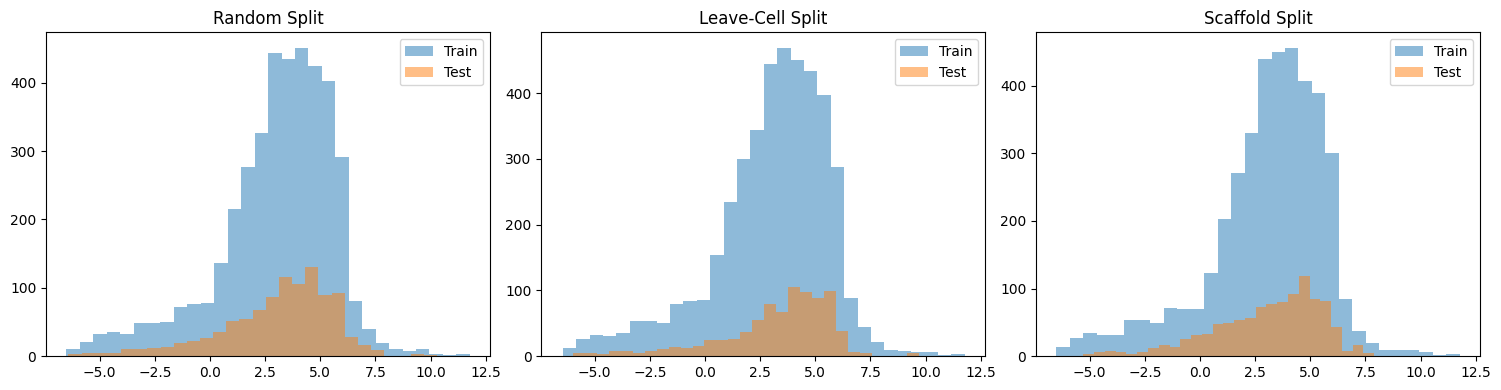

In [ ]:
# 打印三种划分的标签 (LN_IC50) 分布，确认没有极端偏移
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (name, train, test) in zip(axes, [
    ('Random', train_rand, test_rand),
    ('Leave-Cell', train_cell, test_cell),
    ('Scaffold', train_scaf, test_scaf)
]):
    ax.hist(train['LN_IC50'], bins=30, alpha=0.5, label='Train')
    ax.hist(test['LN_IC50'], bins=30, alpha=0.5, label='Test')
    ax.set_title(f'{name} Split')
    ax.legend()

plt.tight_layout()
plt.savefig('three_split.png', dpi=150)
plt.show()